# Proyecto Final: Tráfico aéreo y clima con APIs en la nube y cómputo paralelo

**Pregunta central:** ¿hay relación entre el clima de un aeropuerto y los retrasos de sus vuelos?

## Las 2 APIs que se usan
| API | Qué aporta | Por qué se eligió |
|---|---|---|
| **AirLabs** (`/schedules`) | Vuelos que salen de cada aeropuerto: horario, estado (programado, cancelado, aterrizado...) y minutos de retraso | Da los retrasos, las cancelaciones y los horarios |
| **OpenWeather** (clima actual) | Temperatura, humedad, presión, visibilidad, viento y lluvia en las coordenadas del aeropuerto | Da el clima para relacionarlo con los retrasos |

Con solo estas dos se responden las 5 preguntas de análisis del proyecto.

## Qué tecnología hace cada cosa
| Tecnología | Dónde se usa | Para qué |
|---|---|---|
| **Asyncio** (+ aiohttp) | Sección 4 | Consultar las dos APIs de **todos los aeropuertos al mismo tiempo** (lectura concurrente) |
| **Pandas** | Secciones 5, 7 y 9 | Limpiar los datos, unir vuelos con clima y responder preguntas |
| **MPI4Py** | Sección 6 | **Repartir entre procesos** el cálculo de estadísticas por aeropuerto |
| **CuPy (CUDA)** | Sección 8 | Calcular en la **GPU** la matriz de correlaciones y detectar valores atípicos |
| **Matplotlib** | Sección 10 | Visualizar los resultados |

## Flujo completo
```
APIs (AirLabs + OpenWeather)
        |  asyncio: peticiones concurrentes
        v
   Pandas: limpieza  --->  vuelos.csv
                                |
                                |  MPI4Py: cada proceso calcula las estadísticas de SUS aeropuertos
                                v
                     stats_aeropuertos.csv  --->  Pandas: unir con el clima
                                                        |
                                                        |  CuPy (GPU): correlaciones y atípicos
                                                        v
                                         respuestas + gráficas (Matplotlib)
```



## 1. Instalación de librerías
- **`libopenmpi-dev` y `openmpi-bin`:** el programa MPI real (la "máquina" que lanza y comunica procesos). `mpi4py` es solo el puente para usarlo desde Python.
- **`mpi4py`:** MPI desde Python.
- **`aiohttp`:** cliente HTTP **asíncrono**. La librería `requests` es síncrona y bloquearía cada petición; `aiohttp` permite lanzar muchas a la vez.
- Pandas, NumPy y Matplotlib ya vienen en Colab. CuPy normalmente también (con el entorno de GPU).

In [1]:
!apt-get install -y -qq libopenmpi-dev openmpi-bin > /dev/null
!pip install -q mpi4py aiohttp

## 2. Importaciones y revisión de la GPU
En la GPU se usa un truco sencillo: se importa **CuPy** como `xp`. CuPy tiene casi la misma interfaz que NumPy, solo que ejecuta en la GPU. Si no hubiera GPU, `xp` pasa a ser NumPy y el resto del código funciona igual (en CPU).

In [2]:
import asyncio
import time
import getpass
import aiohttp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import cupy as cp
    cp.cuda.runtime.getDeviceCount()
    xp = cp
    GPU = True
except Exception:
    xp = np
    GPU = False

print("Cálculos numéricos en:", "GPU (CuPy / CUDA)" )

def a_cpu(x):
    return cp.asnumpy(x) if GPU else x

Cálculos numéricos en: GPU (CuPy / CUDA)


## 3. Llaves de las APIs y configuración


In [3]:
AIRLABS_KEY = ("d654d5e5-3507-49ac-90a6-323d9604556e")
OPENWEATHER_KEY = ("8e5da516a8128158113061528caa6ce2")


URL_AIRLABS = "https://airlabs.co/api/v9/schedules"
URL_CLIMA = "https://api.openweathermap.org/data/2.5/weather"


RETRASO_MIN = 15
VISIBILIDAD_BAJA = 5000
MAX_SIMULTANEAS = 5

AEROPUERTOS = {
    "CUU": ("Chihuahua",      28.7029, -105.9647),
    "MEX": ("Ciudad de México", 19.4363, -99.0721),
    "GDL": ("Guadalajara",    20.5218, -103.3112),
    "MTY": ("Monterrey",      25.7785, -100.1069),
    "CUN": ("Cancún",         21.0365,  -86.8771),
    "TIJ": ("Tijuana",        32.5411, -116.9700),
    "JFK": ("Nueva York JFK", 40.6413,  -73.7781),
    "LAX": ("Los Ángeles",    33.9416, -118.4085),
    "ATL": ("Atlanta",        33.6407,  -84.4277),
    "ORD": ("Chicago O'Hare", 41.9742,  -87.9073),
    "DFW": ("Dallas-Fort Worth", 32.8998, -97.0381),
    "MIA": ("Miami",          25.7959,  -80.2870),
    "LHR": ("Londres Heathrow", 51.4700,  -0.4543),
    "MAD": ("Madrid",         40.4983,   -3.5676),
    "CDG": ("París CDG",      49.0097,    2.5479),
}
print(len(AEROPUERTOS), "aeropuertos configurados")

15 aeropuertos configurados


## 4. Asyncio: leer las dos APIs de todos los aeropuertos a la vez

### La idea
Una petición HTTP pasa **casi todo su tiempo esperando** la respuesta del servidor. En código normal (síncrono) el programa se queda detenido en cada espera: 15 aeropuertos x 2 APIs = 30 esperas en fila.

Con **asyncio** el programa, mientras espera una respuesta, aprovecha para lanzar otras peticiones. Las 30 esperas se **traslapan** y el tiempo total se acerca al de la más lenta, no a la suma.

### Piezas
- **Corrutina (`async def`):** función que puede pausarse en un `await`.
- **`await`:** "pausa aquí hasta que esto termine, y mientras tanto el programa avanza otras corrutinas".
- **`asyncio.gather(...)`:** lanza varias corrutinas a la vez y espera a que todas terminen. Devuelve los resultados **en el mismo orden**.
- **`asyncio.Semaphore(n)`:** deja pasar a lo mucho `n` corrutinas a la vez por una sección. Evita mandar 30 peticiones de golpe y que la API nos bloquee (límite de peticiones).
- **Reintentos:** si una petición se agota (*timeout*) o llega incompleta, se reintenta hasta 3 veces con una pausa creciente. Si aun así falla, devuelve un diccionario con el error en lugar de lanzar una excepción, así **no se pierde** la otra API del mismo aeropuerto.
- **`aiohttp.ClientSession`:** una "sesión" que reutiliza conexiones entre peticiones.
- En un notebook ya hay un bucle de eventos corriendo, por eso se usa `await` **directamente** en la celda (no `asyncio.run`).

In [4]:
async def pedir_json(sesion, url, params, semaforo, intentos=3):
    for intento in range(1, intentos + 1):
        try:
            async with semaforo:
                async with sesion.get(url, params=params) as respuesta:
                    return await respuesta.json(content_type=None)
        except (asyncio.TimeoutError, aiohttp.ClientError, ValueError) as error:
            if intento == intentos:
                mensaje = f"sin respuesta tras {intentos} intentos ({type(error).__name__})"
                return {"error": mensaje, "message": mensaje}
            await asyncio.sleep(2 * intento)


async def consultar_aeropuerto(sesion, semaforo, iata, lat, lon):
    tarea_vuelos = pedir_json(sesion, URL_AIRLABS,
                              {"api_key": AIRLABS_KEY, "dep_iata": iata}, semaforo)
    tarea_clima = pedir_json(sesion, URL_CLIMA,
                             {"lat": lat, "lon": lon, "appid": OPENWEATHER_KEY, "units": "metric"}, semaforo)
    vuelos, clima = await asyncio.gather(tarea_vuelos, tarea_clima)
    return iata, vuelos, clima


async def descargar_todo():
    semaforo = asyncio.Semaphore(MAX_SIMULTANEAS)
    espera_maxima = aiohttp.ClientTimeout(total=30)
    async with aiohttp.ClientSession(timeout=espera_maxima) as sesion:
        tareas = [consultar_aeropuerto(sesion, semaforo, iata, lat, lon)
                  for iata, (_, lat, lon) in AEROPUERTOS.items()]
        return await asyncio.gather(*tareas, return_exceptions=True)


t0 = time.perf_counter()
resultados = await descargar_todo()
print(f"{len(resultados)} aeropuertos consultados (2 APIs cada uno) en {time.perf_counter() - t0:.2f} s")

15 aeropuertos consultados (2 APIs cada uno) en 1.96 s


## 5. Pandas: extraer, limpiar y guardar los datos

Cada respuesta es un JSON (diccionarios y listas). Aquí:
1. Se **extraen solo los campos necesarios** y se arman dos tablas (DataFrames): vuelos y clima.
2. Se **limpian**: los retrasos vienen vacíos cuando no hay retraso (se convierten a 0), se crean las columnas `retrasado`, `cancelado` y `hora`, y se quitan duplicados.
3. Los vuelos se guardan en **`vuelos.csv`**, porque el siguiente paso (MPI) corre como un **programa aparte** que lee ese archivo.

Si una API devuelve un error (por ejemplo, llave inválida o límite de peticiones), se imprime el mensaje para que sepas qué pasó.

In [5]:
filas_vuelos = []
filas_clima = []

for r in resultados:
    if isinstance(r, Exception):
        print("Falló una consulta:", repr(r))
        continue

    iata, vuelos_json, clima_json = r

    if isinstance(vuelos_json, dict) and "response" in vuelos_json:
        for v in vuelos_json["response"]:
            filas_vuelos.append({
                "dep_iata": iata,
                "arr_iata": v.get("arr_iata"),
                "airline_iata": v.get("airline_iata"),
                "flight_iata": v.get("flight_iata"),
                "status": v.get("status"),
                "dep_time": v.get("dep_time"),
                "dep_delayed": v.get("dep_delayed"),
            })
    else:
        print(f"AirLabs ({iata}):", vuelos_json.get("error", vuelos_json) if isinstance(vuelos_json, dict) else vuelos_json)

    if isinstance(clima_json, dict) and "main" in clima_json:
        filas_clima.append({
            "dep_iata": iata,
            "temp": clima_json["main"]["temp"],
            "humedad": clima_json["main"]["humidity"],
            "presion": clima_json["main"]["pressure"],
            "visibilidad": clima_json.get("visibility", 10000),
            "viento": clima_json.get("wind", {}).get("speed", 0.0),
            "lluvia_mm": clima_json.get("rain", {}).get("1h", 0.0),
            "condicion": clima_json["weather"][0]["main"],
        })
    else:
        print(f"OpenWeather ({iata}):", clima_json.get("message", clima_json) if isinstance(clima_json, dict) else clima_json)

vuelos = pd.DataFrame(filas_vuelos)
clima = pd.DataFrame(filas_clima)

if vuelos.empty or clima.empty:
    raise RuntimeError("No llegaron datos. Revisa los mensajes de arriba (llaves, límite de peticiones, etc.).")

vuelos["dep_delayed"] = pd.to_numeric(vuelos["dep_delayed"], errors="coerce").fillna(0)
vuelos["retrasado"] = vuelos["dep_delayed"] >= RETRASO_MIN
vuelos["cancelado"] = vuelos["status"] == "cancelled"
vuelos["hora"] = pd.to_datetime(vuelos["dep_time"], errors="coerce").dt.hour
vuelos = vuelos.drop_duplicates(subset=["flight_iata", "dep_iata", "dep_time"])

vuelos.to_csv("vuelos.csv", index=False)

print("Vuelos:", len(vuelos), "| Aeropuertos con vuelos:", vuelos["dep_iata"].nunique(),
      "| Aeropuertos con clima:", len(clima))
print("Vuelos retrasados:", int(vuelos["retrasado"].sum()), "| cancelados:", int(vuelos["cancelado"].sum()))
vuelos.head()

Vuelos: 1332 | Aeropuertos con vuelos: 15 | Aeropuertos con clima: 15
Vuelos retrasados: 191 | cancelados: 2


,dep_iata,arr_iata,airline_iata,flight_iata,status,dep_time,dep_delayed,retrasado,cancelado,hora
0,CUU,MZT,VB,VB9105,landed,2026-11-23 20:08,0.0,False,False,20
1,CUU,MEX,AM,AM149,active,2026-11-23 20:48,32.0,True,False,20
2,CUU,MEX,WS,WS6196,active,2026-11-23 20:48,32.0,True,False,20
3,CUU,GDL,CM,CM3166,scheduled,2026-11-23 21:58,0.0,False,False,21
4,CUU,GDL,Y4,Y41223,scheduled,2026-11-23 21:58,0.0,False,False,21


## 6. MPI4Py: repartir el cálculo por aeropuerto entre procesos

### La idea
MPI lanza **varias copias del mismo programa (procesos)**. Cada copia sabe quién es mediante su **`rank`** (0, 1, ...) y cuántas hay (**`size`**). Los procesos **no comparten memoria**; solo se pasan mensajes. Es el modelo **SPMD**: mismo programa, datos distintos.

### Qué se reparte aquí
Las estadísticas **por aeropuerto** (número de vuelos, retraso promedio, % retrasados, cancelados) son independientes entre aeropuertos, así que se pueden repartir:
- Cada proceso toma **sus** aeropuertos con `aeropuertos[rank::size]` (reparto "por turnos", como repartir cartas).
- Calcula las estadísticas de los suyos con Pandas.
- **`comm.gather`** junta los resultados en el proceso 0, que guarda `stats_aeropuertos.csv`.

### Por qué un archivo `.py` aparte
MPI necesita lanzar **procesos nuevos**, y un notebook es un solo proceso. Por eso el código MPI se escribe a un archivo con `%%writefile` y se ejecuta con **`mpiexec`**. Los datos viajan por archivos (`vuelos.csv` de entrada y `stats_aeropuertos.csv` de salida).

> Colab tiene pocos núcleos (normalmente 2), así que usamos 2 procesos. Con tan pocos datos MPI **no hace más rápido** el cálculo (lanzar procesos cuesta más que lo que se ahorra); se usa para aplicar la distribución del procesamiento que pide el proyecto.

In [6]:
%%writefile mpi_estadisticas.py
from mpi4py import MPI
import pandas as pd

comm = MPI.COMM_WORLD
rank = comm.Get_rank()
size = comm.Get_size()

df = pd.read_csv("vuelos.csv")

aeropuertos = sorted(df["dep_iata"].unique())

mios = aeropuertos[rank::size]

parte = df[df["dep_iata"].isin(mios)]

stats = parte.groupby("dep_iata").agg(
    vuelos=("status", "size"),
    retraso_prom=("dep_delayed", "mean"),
    pct_retrasados=("retrasado", "mean"),
    cancelados=("cancelado", "sum"),
).reset_index()
stats["pct_retrasados"] = stats["pct_retrasados"] * 100

print(f"[proceso {rank} de {size}] calculó {len(mios)} aeropuertos: {mios}")

todos = comm.gather(stats, root=0)

if rank == 0:
    pd.concat(todos).sort_values("dep_iata").to_csv("stats_aeropuertos.csv", index=False)
    print("[proceso 0] guardó stats_aeropuertos.csv")

Writing mpi_estadisticas.py


In [7]:
!mpiexec -n 2 --allow-run-as-root --oversubscribe python mpi_estadisticas.py

[proceso 1 de 2] calculó 7 aeropuertos: ['CDG', 'CUU', 'GDL', 'LAX', 'MAD', 'MIA', 'ORD']
[proceso 0 de 2] calculó 8 aeropuertos: ['ATL', 'CUN', 'DFW', 'JFK', 'LHR', 'MEX', 'MTY', 'TIJ']
[proceso 0] guardó stats_aeropuertos.csv


## 7. Pandas: unir las estadísticas con el clima
Se juntan las dos tablas por el código del aeropuerto (`dep_iata`). Es el equivalente a un `JOIN` de SQL. Queda **una fila por aeropuerto** con sus estadísticas de vuelos y su clima.

In [8]:
stats = pd.read_csv("stats_aeropuertos.csv")

datos = stats.merge(clima, on="dep_iata")

datos["nombre"] = datos["dep_iata"].map(lambda iata: AEROPUERTOS[iata][0])

datos["n_retrasados"] = (datos["pct_retrasados"] / 100 * datos["vuelos"]).round()

datos[["dep_iata", "nombre", "vuelos", "retraso_prom", "pct_retrasados", "cancelados",
       "temp", "humedad", "presion", "visibilidad", "viento", "lluvia_mm", "condicion"]]

,dep_iata,nombre,vuelos,retraso_prom,pct_retrasados,cancelados,temp,humedad,presion,visibilidad,viento,lluvia_mm,condicion
0,ATL,Atlanta,100,13.840000,27.000000,0,12.86,80,1020,10000,2.57,0.0,Clear
1,CDG,París CDG,100,1.300000,2.000000,0,1.90,90,1023,9000,4.12,0.0,Clouds
2,CUN,Cancún,63,26.619048,11.111111,0,23.95,100,1015,7384,0.89,0.2,Rain
3,CUU,Chihuahua,19,3.842105,10.526316,0,10.16,63,1018,10000,1.25,0.0,Clear
4,DFW,Dallas-Fort Worth,100,10.380000,18.000000,0,9.72,50,1025,10000,0.89,0.0,Clouds
5,GDL,Guadalajara,100,3.880000,7.000000,0,19.19,69,1014,10000,1.62,0.0,Clouds
6,JFK,Nueva York JFK,100,21.130000,24.000000,0,11.62,54,1017,10000,8.94,0.0,Clouds
7,LAX,Los Ángeles,100,2.640000,8.000000,2,17.18,70,1021,10000,5.14,0.0,Clouds
8,LHR,Londres Heathrow,100,0.000000,0.000000,0,1.84,91,1020,10000,4.12,0.0,Clouds
9,MAD,Madrid,100,23.060000,6.000000,0,5.32,82,1020,10000,1.54,0.0,Clear


## 8. CuPy (CUDA): correlaciones y valores atípicos en la GPU

### Qué es CuPy
Biblioteca con la interfaz de NumPy que ejecuta los cálculos en la **GPU NVIDIA** mediante **CUDA**. El flujo es: copiar los datos de la memoria normal a la memoria de la GPU (`xp.asarray`), calcular allí, y traer el resultado de vuelta (`a_cpu`).

### Qué se calcula
1. **Matriz de correlación** (`corrcoef`): qué tan relacionadas están todas las variables entre sí (retrasos, tráfico y clima). Va de -1 a 1: cerca de 1 = suben juntas, cerca de -1 = una sube y la otra baja, cerca de 0 = no hay relación lineal.
2. **Valores atípicos** con la **puntuación z**: `z = (valor - promedio) / desviación estándar`. Si `|z| > 3`, el retraso está a más de 3 desviaciones del promedio y se marca como atípico.

> Con tan pocos datos la GPU **no es más rápida** que la CPU (copiar a la GPU cuesta más que calcular). Se usa para aplicar la aceleración con CUDA que pide el proyecto; el beneficio real aparece con millones de datos.

In [9]:
variables = ["retraso_prom", "pct_retrasados", "vuelos",
             "temp", "humedad", "presion", "visibilidad", "viento", "lluvia_mm"]

variables = [v for v in variables if datos[v].std() > 0]

matriz = xp.asarray(datos[variables].to_numpy(dtype="float64"))

corr = a_cpu(xp.corrcoef(matriz, rowvar=False))
tabla_corr = pd.DataFrame(corr, index=variables, columns=variables)

retrasos = xp.asarray(vuelos["dep_delayed"].to_numpy(dtype="float64"))
desviacion = float(retrasos.std())

if desviacion > 0:
    z = (retrasos - retrasos.mean()) / desviacion
    vuelos["atipico"] = a_cpu(xp.abs(z) > 3)
else:
    vuelos["atipico"] = False

print("Matriz de correlación calculada con", "CuPy (GPU)" if GPU else "NumPy (CPU)")
print("Vuelos con retraso atípico (|z| > 3):", int(vuelos["atipico"].sum()), "de", len(vuelos))
tabla_corr.round(2)

Matriz de correlación calculada con CuPy (GPU)
Vuelos con retraso atípico (|z| > 3): 22 de 1332


,retraso_prom,pct_retrasados,vuelos,temp,humedad,presion,visibilidad,viento,lluvia_mm
retraso_prom,1.00,0.51,-0.09,0.32,0.04,-0.13,-0.08,-0.05,0.48
pct_retrasados,0.51,1.00,-0.02,0.34,-0.39,0.04,-0.08,0.09,-0.10
vuelos,-0.09,-0.02,1.00,-0.17,0.06,0.25,-0.00,0.37,-0.29
temp,0.32,0.34,-0.17,1.00,0.01,-0.67,-0.23,-0.35,0.44
humedad,0.04,-0.39,0.06,0.01,1.00,-0.14,-0.51,-0.24,0.49
presion,-0.13,0.04,0.25,-0.67,-0.14,1.00,0.19,0.23,-0.33
visibilidad,-0.08,-0.08,-0.00,-0.23,-0.51,0.19,1.00,0.21,-0.39
viento,-0.05,0.09,0.37,-0.35,-0.24,0.23,0.21,1.00,-0.27
lluvia_mm,0.48,-0.10,-0.29,0.44,0.49,-0.33,-0.39,-0.27,1.00


## 9. Respuestas a las preguntas de análisis
Todas salen de **tus datos de este momento**. Recuerda que es una **foto instantánea** (un aeropuerto = un punto), así que con ~15 aeropuertos las correlaciones son una **pista**, no una prueba.

In [10]:
clima_vars = [v for v in ["temp", "humedad", "presion", "visibilidad", "viento", "lluvia_mm"] if v in variables]
objetivos = [v for v in ["retraso_prom", "pct_retrasados"] if v in variables]

print("P1. ¿Hay relación entre clima y retrasos?")
if objetivos and clima_vars:
    print("Correlación de cada variable del clima con los retrasos (de -1 a 1):")
    print(tabla_corr.loc[clima_vars, objetivos].round(2))
    mejor = tabla_corr.loc[clima_vars, objetivos[-1]].abs().idxmax()
    print(f"-> La variable con mayor relación (en valor absoluto) con '{objetivos[-1]}' es '{mejor}' "
          f"({tabla_corr.loc[mejor, objetivos[-1]]:.2f}).")
else:
    print("No hay suficientes datos con variación (por ejemplo, no hubo retrasos) para calcular correlaciones.")

print("\nP2. ¿Aumentan los retrasos con lluvia o baja visibilidad?")
datos["mal_clima"] = (datos["lluvia_mm"] > 0) | (datos["visibilidad"] < VISIBILIDAD_BAJA)
grupos = datos.groupby("mal_clima")["pct_retrasados"].agg(["mean", "count"])
grupos.index = grupos.index.map({True: "Con lluvia / baja visibilidad", False: "Clima normal"})
grupos.columns = ["% retrasados (promedio)", "aeropuertos"]
print(grupos.round(1))
if len(grupos) < 2:
    print("-> Todos los aeropuertos están en el mismo grupo ahora mismo; no se puede comparar lluvia / baja visibilidad. Vuelve a correrlo en otro momento.")
    alt = datos.groupby("condicion")[["pct_retrasados", "retraso_prom"]].mean()
    alt["aeropuertos"] = datos.groupby("condicion").size()
    alt.columns = ["% retrasados (promedio)", "retraso prom. (min)", "aeropuertos"]
    print("\nComparación alternativa por condición del cielo:")
    print(alt.round(1))

print("\nP3. Aeropuertos con más vuelos retrasados:")
ranking = datos.sort_values(["n_retrasados", "pct_retrasados"], ascending=False)
print(ranking[["dep_iata", "nombre", "vuelos", "n_retrasados", "pct_retrasados", "retraso_prom"]].head(5).round(1).to_string(index=False))

print("\nP4. Salidas programadas por hora del día (todos los aeropuertos):")
por_hora = vuelos.dropna(subset=["hora"]).groupby("hora").size()
if len(por_hora):
    print(f"-> Hora con más salidas: {int(por_hora.idxmax())}:00 ({int(por_hora.max())} vuelos) | "
          f"hora con menos: {int(por_hora.idxmin())}:00 ({int(por_hora.min())} vuelos)")

print("\nP5. Correlación de las condiciones ambientales con la cantidad de vuelos:")
if "vuelos" in variables and clima_vars:
    print(tabla_corr.loc[clima_vars, "vuelos"].round(2).to_string())
else:
    print("No hay variación suficiente para calcular correlaciones.")

P1. ¿Hay relación entre clima y retrasos?
Correlación de cada variable del clima con los retrasos (de -1 a 1):
             retraso_prom  pct_retrasados
temp                 0.32            0.34
humedad              0.04           -0.39
presion             -0.13            0.04
visibilidad         -0.08           -0.08
viento              -0.05            0.09
lluvia_mm            0.48           -0.10
-> La variable con mayor relación (en valor absoluto) con 'pct_retrasados' es 'humedad' (-0.39).

P2. ¿Aumentan los retrasos con lluvia o baja visibilidad?
                               % retrasados (promedio)  aeropuertos
mal_clima                                                          
Clima normal                                      14.1           13
Con lluvia / baja visibilidad                     16.1            2

P3. Aeropuertos con más vuelos retrasados:
dep_iata            nombre  vuelos  n_retrasados  pct_retrasados  retraso_prom
     ATL           Atlanta     100          

### Revisión de robustez (antes de concluir)
Con tan pocos aeropuertos, **un solo aeropuerto con retrasos muy grandes puede inventar una correlación**. Esta celda revisa tres cosas:
1. En qué aeropuertos están los retrasos atípicos.
2. Cómo cambian las correlaciones **sin** el aeropuerto de mayor retraso promedio. Si cambian mucho, esa relación no es confiable.
3. Cuántos aeropuertos llegaron al **tope de vuelos** que devuelve la consulta de AirLabs (si muchos tienen el mismo número, la variable `vuelos` es solo el tope de la API y no el tráfico real).

In [11]:
print("Vuelos con retraso atípico (|z| > 3) por aeropuerto:")
print(vuelos[vuelos["atipico"]].groupby("dep_iata").size().sort_values(ascending=False).to_string())

peor = datos.loc[datos["retraso_prom"].idxmax(), "dep_iata"]
sin = datos[datos["dep_iata"] != peor]
print(f"\nCorrelación con los retrasos SIN {peor} ({len(sin)} aeropuertos):")
print(sin[clima_vars + objetivos].corr().loc[clima_vars, objetivos].round(2))

tope = datos["vuelos"].max()
print(f"\nAeropuertos con {tope} vuelos (probable tope de la API): {(datos['vuelos'] == tope).sum()} de {len(datos)}")

Vuelos con retraso atípico (|z| > 3) por aeropuerto:
dep_iata
JFK    6
MAD    6
MTY    5
MIA    2
CUN    1
GDL    1
TIJ    1

Correlación con los retrasos SIN CUN (14 aeropuertos):
             retraso_prom  pct_retrasados
temp                 0.14            0.43
humedad             -0.26           -0.39
presion              0.03            0.01
visibilidad          0.14           -0.13
viento               0.09            0.06
lluvia_mm             NaN             NaN

Aeropuertos con 100 vuelos (probable tope de la API): 12 de 15


## 10. Visualización con Matplotlib

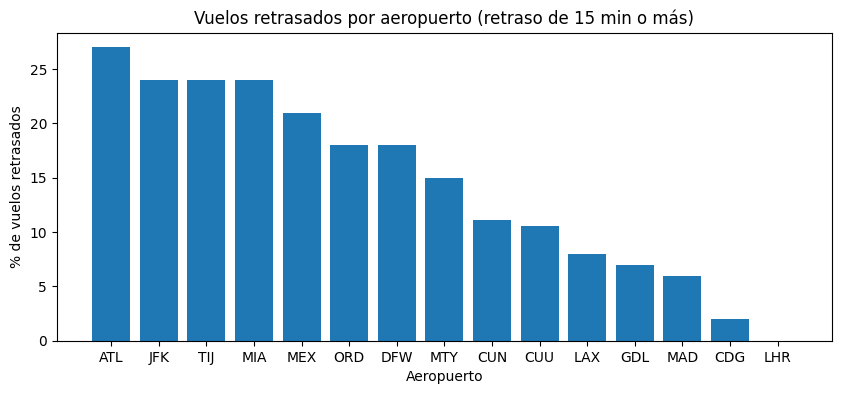

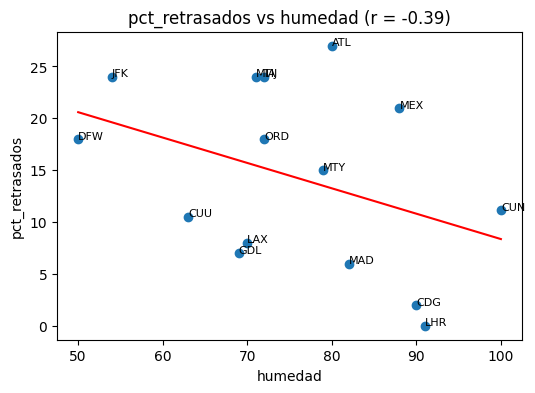

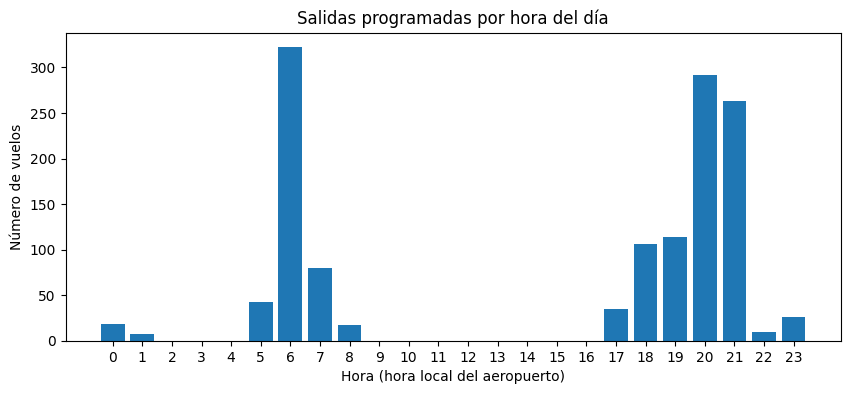

In [12]:
orden = datos.sort_values("pct_retrasados", ascending=False)
plt.figure(figsize=(10, 4))
plt.bar(orden["dep_iata"], orden["pct_retrasados"])
plt.title("Vuelos retrasados por aeropuerto (retraso de 15 min o más)")
plt.xlabel("Aeropuerto"); plt.ylabel("% de vuelos retrasados")
plt.show()

if objetivos and clima_vars:
    objetivo = objetivos[-1]
    var = tabla_corr.loc[clima_vars, objetivo].abs().idxmax()
    plt.figure(figsize=(6, 4))
    plt.scatter(datos[var], datos[objetivo])
    for _, f in datos.iterrows():
        plt.annotate(f["dep_iata"], (f[var], f[objetivo]), fontsize=8)
    if datos[var].nunique() > 1:
        m, b = np.polyfit(datos[var], datos[objetivo], 1)
        xs = np.linspace(datos[var].min(), datos[var].max(), 50)
        plt.plot(xs, m * xs + b, color="red")
    plt.title(f"{objetivo} vs {var} (r = {tabla_corr.loc[var, objetivo]:.2f})")
    plt.xlabel(var); plt.ylabel(objetivo)
    plt.show()

if len(por_hora):
    plt.figure(figsize=(10, 4))
    plt.bar(por_hora.index, por_hora.values)
    plt.title("Salidas programadas por hora del día")
    plt.xlabel("Hora (hora local del aeropuerto)"); plt.ylabel("Número de vuelos")
    plt.xticks(range(0, 24))
    plt.show()

●	¿Hay relación entre clima y retrasos? No hay evidencia clara. Con 15 aeropuertos haría falta una correlación mayor a 0.51 en valor absoluto para considerarla significativa (5%) y ninguna la alcanza. Con el porcentaje de retrasados la mayor es la humedad (-0.39, negativa: más humedad, menos retrasados, lo contrario de lo esperado) y con el retraso promedio la lluvia (0.48). Esa última depende de un solo aeropuerto: Cancún es el único con lluvia medible, y sin él la lluvia es constante y no se puede calcular. Las correlaciones de temperatura y humedad con el retraso promedio cambian al quitar Cancún (0.32 pasa a 0.14 y 0.04 a -0.26), así que tampoco son estables.  
●	¿Aumentan los retrasos cuando hay lluvia o baja visibilidad? Solo hay 2 aeropuertos en esa condición y la diferencia es pequeña: 16.1% de vuelos retrasados contra 14.1% con clima normal. Además van en direcciones opuestas: Ciudad de México (visibilidad de 4828 m) tiene 21.0%, por encima del promedio normal, pero Cancún (lluvia) tiene 11.1%, por debajo. Por condición del cielo tampoco hay un patrón de que el peor clima traiga más retrasos: despejado 18.3%, lluvia 16.1% y nubes 10.6%. Con 2 aeropuertos no es posible concluir.  
●	¿Qué aeropuertos presentan mayor cantidad de retrasos? Atlanta (27 vuelos, 27.0%), Nueva York JFK (24, 24.0%), Miami (24, 24.0%), Ciudad de México (21, 21.0%) y Dallas-Fort Worth (18, 18.0%). Por retraso promedio el orden cambia: Cancún (26.6 min), Madrid (23.1) y JFK (21.1). Madrid tiene solo 6% de vuelos retrasados pero 6 retrasos atípicos que elevan su promedio. Los de menos retrasos fueron Londres Heathrow (0.0%) y París CDG (2.0%).  
●	¿Cómo cambia la actividad aérea en una región durante el día? Considerando los 15 aeropuertos juntos, la hora con más salidas programadas fue las 6:00 (322 vuelos) y la de menos la 1:00 (7 vuelos): la actividad crece fuerte por la mañana y baja de madrugada. El análisis no separa por región y mezcla horas locales de distintos aeropuertos, y corresponde a la ventana de vuelos que devolvió la API, no a un día completo.  
●	¿Qué condiciones ambientales coinciden con mayor tráfico aéreo? Las correlaciones más altas con el número de vuelos fueron el viento (0.37), la lluvia (-0.29) y la presión (0.25); temperatura (-0.17), humedad (0.06) y visibilidad (0.00) quedaron cerca de cero. Ninguna es significativa y no es confiable: 12 de los 15 aeropuertos tienen exactamente 100 vuelos, que parece ser el máximo que devuelve la consulta de AirLabs, así que esa variable es en gran parte el tope de la API y no el tráfico real.


## 11. Guía para exponer

**En una frase:** se descargan en paralelo vuelos y clima de 15 aeropuertos, se limpian con Pandas, se calculan estadísticas por aeropuerto repartidas con MPI, se calculan correlaciones y atípicos en la GPU con CuPy, y se responden las preguntas con gráficas.

**Orden para explicarlo**
1. **Asyncio (sec. 4):** las peticiones HTTP son esperas de red; `gather` las traslapa y `Semaphore` limita cuántas van a la vez.
2. **Pandas (sec. 5 y 7):** del JSON a tablas; limpieza (retraso vacío = 0, columnas `retrasado`, `cancelado`, `hora`); `merge` para unir vuelos y clima.
3. **MPI4Py (sec. 6):** SPMD, `rank`/`size`, reparto `aeropuertos[rank::size]`, `gather` al proceso 0. Se corre con `mpiexec` porque necesita varios procesos.
4. **CuPy (sec. 8):** misma interfaz que NumPy pero en la GPU; datos a GPU → cálculo → resultado a CPU.
5. **Resultados (sec. 9 y 10):** respuestas a las 5 preguntas con tus datos.

**Preguntas que pueden hacerte**
- *¿Por qué asyncio y no threads?* Para tareas de espera de red, asyncio es más ligero: un solo hilo y miles de esperas simultáneas, sin los problemas de sincronización de los threads.
- *¿Para qué sirve el Semaphore?* Para limitar las peticiones simultáneas y no pasar el límite de las APIs.
- *¿Por qué MPI usa un archivo `.py` aparte?* Porque MPI lanza procesos nuevos; un notebook es un solo proceso.
- *¿MPI y la GPU aceleraron algo aquí?* No: son pocos datos y el costo de lanzar procesos o copiar a la GPU es mayor que el cálculo. Se usan para aplicar la técnica; el beneficio llega con muchos datos.
- *¿Por qué el resultado no es concluyente?* Son pocos aeropuertos, una sola foto del clima y retrasos que dependen de muchas otras causas (tráfico, tripulación, mantenimiento). Para concluir mejor habría que repetir la medición durante varios días.
- *¿Cómo se definió "retrasado"?* Salida con 15 minutos o más de retraso.
- *¿Y los atípicos?* Retrasos con puntuación z mayor a 3 en valor absoluto.

**Limitaciones que conviene mencionar:** el plan gratuito de las APIs limita las peticiones y los datos (AirLabs devuelve como máximo 100 vuelos por aeropuerto, así que la cantidad de vuelos de varios aeropuertos es solo ese tope); algunas consultas pueden fallar por *timeout* y el notebook las reintenta, pero si siguen fallando se pierde ese aeropuerto; los vuelos que aún no han salido tienen retraso 0 porque todavía no se conoce, lo que subestima el porcentaje de retrasados; el clima es el de *ahora* mientras los vuelos son los próximos de la lista de AirLabs; la correlación no implica causalidad.